# 01 FIFA clean

**Owner:** Sahil

1. Load `male_players.csv` and assert every regression check in CLAUDE.md §7. Stop if any fails.
2. Add edition label, edition date, primary position, position group.
3. Log missing values and outliers (nothing is dropped from the panel).
4. Build the cohort (CLAUDE.md §6): each player enters once, at his **first** edition from FIFA 15 to
   FIFA 18 in which he is aged 21 or under.
5. Build the learning cohorts (entries FIFA 15–20, same first-entry rule) for chart 7.

**Outputs:** `data/clean/fifa_panel.parquet`, `data/clean/cohort.parquet`,
`data/clean/learning_cohorts.parquet`, section `01` of `reports/data_quality.md`.

In `cohort.parquet`, every original FIFA column (`overall`, `potential`, `age`, `club_name`, attributes, …)
holds the value **at the entry edition**. Outcome columns (`peak_later`, `status`, `gap`, …) are derived.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, dq, cohort as ch

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

CHECKS, NOTES = [], []
def check(name, passed, detail=""):
    CHECKS.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": detail})
    print(("PASS" if passed else "FAIL"), "-", name, ("| " + detail if detail else ""))
    return passed

log = dq.FilterLog()

## 1. Load and inspect

In [2]:
raw = pd.read_csv(config.FIFA_PLAYERS, low_memory=False)
print(raw.shape)
print(raw.dtypes.value_counts())
with pd.option_context("display.max_rows", 120):
    display(raw.dtypes.to_frame("dtype").T)
display(raw.head(3))

(180021, 109)
str        46
int64      43
float64    20
Name: count, dtype: int64


,player_id,player_url,fifa_version,fifa_update,update_as_of,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,dob,height_cm,weight_kg,club_team_id,club_name,league_id,league_name,league_level,club_position,club_jersey_number,club_loaned_from,club_joined_date,club_contract_valid_until_year,nationality_id,nationality_name,nation_team_id,nation_position,nation_jersey_number,preferred_foot,weak_foot,skill_moves,international_reputation,work_rate,body_type,real_face,release_clause_eur,player_tags,player_traits,pace,shooting,passing,dribbling,defending,physic,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk
dtype,int64,str,float64,float64,str,str,str,str,int64,int64,float64,float64,int64,str,int64,int64,float64,str,float64,str,float64,str,float64,str,str,float64,int64,str,float64,str,float64,str,int64,int64,int64,str,str,str,float64,str,str,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,float64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str


,player_id,player_url,fifa_version,fifa_update,update_as_of,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,dob,height_cm,weight_kg,club_team_id,club_name,league_id,league_name,league_level,club_position,club_jersey_number,club_loaned_from,club_joined_date,club_contract_valid_until_year,nationality_id,nationality_name,nation_team_id,nation_position,nation_jersey_number,preferred_foot,weak_foot,skill_moves,international_reputation,work_rate,body_type,real_face,release_clause_eur,player_tags,player_traits,pace,shooting,passing,dribbling,defending,physic,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk
0,231747,/player/231747/kylian-mbappe/240002,24.0,2.0,2023-09-22,K. Mbappé,Kylian Mbappé Lottin,"ST, LW",91,94,181500000.0,230000.0,24,1998-12-20,182,75,73.0,Paris Saint Germain,16.0,Ligue 1,1.0,LW,7.0,NaN,2018-07-01,2024.0,18,France,1335.0,LW,10.0,Right,4,5,5,High/Low,Unique,Yes,349400000.0,"#Speedster, #Dribbler, #Acrobat, #Clinical fin...","Quick Step +, Rapid, Flair, Trivela",97.0,90.0,80.0,92.0,36.0,78.0,78,94,73,86,84,93,80,69,71,92,97,97,93,93,82,90,88,88,77,83,64,38,93,83,84,88.0,26,34,32,13,5,7,11,6,NaN,90+3,90+3,90+3,91,91,91,91,91,89+3,89+3,89+3,89+3,81+3,81+3,81+3,89+3,68+3,63+3,63+3,63+3,68+3,63+3,54+3,54+3,54+3,63+3,18+3
1,239085,/player/239085/erling-haaland/240002,24.0,2.0,2023-09-22,E. Haaland,Erling Braut Haaland,ST,91,94,185000000.0,340000.0,22,2000-07-21,195,94,10.0,Manchester City,13.0,Premier League,1.0,ST,9.0,NaN,2022-07-01,2027.0,36,Norway,1352.0,ST,9.0,Left,3,3,5,High/Medium,Unique,Yes,356100000.0,"#Aerial threat, #Distance shooter, #Strength, ...","Acrobatic +, Power Header, Quick Step",89.0,93.0,66.0,80.0,45.0,88.0,47,96,83,77,90,79,77,62,53,82,82,94,76,94,72,94,93,76,93,86,87,43,96,74,84,87.0,38,47,29,7,14,13,11,7,NaN,90+3,90+3,90+3,82,86,86,86,82,82+3,82+3,82+3,79+3,74+3,74+3,74+3,79+3,62+3,63+3,63+3,63+3,62+3,60+3,62+3,62+3,62+3,60+3,19+3
2,192985,/player/192985/kevin-de-bruyne/240002,24.0,2.0,2023-09-22,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,103000000.0,350000.0,32,1991-06-28,181,75,10.0,Manchester City,13.0,Premier League,1.0,SUB,17.0,NaN,2015-08-30,2025.0,7,Belgium,1325.0,CAM,7.0,Right,5,4,5,High/Medium,Unique,Yes,190600000.0,"#Dribbler, #Playmaker, #Distance shooter, #Cro...","Pinged Pass +, Dead Ball, Incisive Pass, Long ...",72.0,88.0,94.0,87.0,65.0,78.0,95,85,55,94,83,86,92,83,94,92,72,72,74,92,78,92,72,88,74,92,75,66,88,95,83,88.0,66,70,53,15,13,5,10,13,NaN,83+3,83+3,83+3,87,88,88,88,87,89+2,89+2,89+2,88+3,90+1,90+1,90+1,88+3,79+3,80+3,80+3,80+3,79+3,75+3,70+3,70+3,70+3,75+3,21+3


## 2. Regression checks (CLAUDE.md §7). The notebook stops here if any fails

In [3]:
ok = []
ok.append(check("Shape is 180,021 rows x 109 columns", raw.shape == config.EXPECTED_SHAPE, f"got {raw.shape}"))
ok.append(check("53,111 unique player_id", raw["player_id"].nunique() == config.EXPECTED_UNIQUE_PLAYERS,
                f"got {raw['player_id'].nunique():,}"))
n_dup = int(raw.duplicated(["player_id", "fifa_version"]).sum())
ok.append(check("No duplicate (player_id, fifa_version) pairs", n_dup == 0, f"{n_dup} duplicates"))

ed = raw["fifa_version"].astype(int)
per_ed = pd.DataFrame({
    "rows": raw.groupby(ed).size(),
    "date": raw.groupby(ed)["update_as_of"].agg(lambda s: "|".join(sorted(s.unique()))),
    "u21_pot85": raw[(raw["age"] <= 21) & (raw["potential"] >= 85)].groupby(ed.rename("fifa_version")).size(),
})
per_ed["exp_rows"] = per_ed.index.map(config.EXPECTED_ROWS_PER_EDITION)
per_ed["exp_date"] = per_ed.index.map(config.EXPECTED_EDITION_DATES)
per_ed["exp_u21_pot85"] = per_ed.index.map(config.EXPECTED_U21_POT85_PER_EDITION)
display(per_ed)
ok.append(check("Rows per edition match", (per_ed["rows"] == per_ed["exp_rows"]).all()))
ok.append(check("Date per edition matches (one date each)", (per_ed["date"] == per_ed["exp_date"]).all()))
ok.append(check("Under-21s with potential >= 85 per edition match",
                (per_ed["u21_pot85"] == per_ed["exp_u21_pot85"]).all()))

PASS - Shape is 180,021 rows x 109 columns | got (180021, 109)
PASS - 53,111 unique player_id | got 53,111
PASS - No duplicate (player_id, fifa_version) pairs | 0 duplicates


,rows,date,u21_pot85,exp_rows,exp_date,exp_u21_pot85
fifa_version,,,,,,
15,16182,2014-09-18,48,16182,2014-09-18,48
16,16706,2015-09-21,82,16706,2015-09-21,82
17,17596,2016-09-20,106,17596,2016-09-20,106
18,17954,2017-09-18,137,17954,2017-09-18,137
19,18086,2018-08-21,144,18086,2018-08-21,144
20,18483,2019-09-19,170,18483,2019-09-19,170
21,18892,2020-09-23,145,18892,2020-09-23,145
22,19239,2021-09-23,120,19239,2021-09-23,120
23,18533,2022-09-26,127,18533,2022-09-26,127


PASS - Rows per edition match 
PASS - Date per edition matches (one date each) 
PASS - Under-21s with potential >= 85 per edition match 


In [4]:
# FIFA 15 under-21s by potential band, peak later rating across ALL later editions.
# Before the first-entry and already-peaked rules (CLAUDE.md §7).
f15 = raw[(ed == 15) & (raw["age"] <= 21)].copy()
later_peak = raw[ed > 15].groupby("player_id")["overall"].max()
f15["peak_later"] = f15["player_id"].map(later_peak)
f15["band"] = ch.potential_band(f15["potential"])
f15["diff"] = f15["peak_later"] - f15["potential"]
reg = f15.groupby("band", observed=True).agg(
    n=("player_id", "size"),
    reached=("diff", lambda s: int((s >= 0).sum())),
    vanished=("peak_later", lambda s: int(s.isna().sum())),
    mean_diff=("diff", lambda s: round(s.mean(), 2)))
reg.index = reg.index.astype(str)
exp = pd.DataFrame(config.EXPECTED_FIFA15_BANDS, index=["n", "reached", "vanished", "mean_diff"]).T.reindex(reg.index)
reg_cmp = reg.join(exp.add_suffix("_expected"))
display(reg_cmp)

ok.append(check("FIFA 15 under-21s = 4,594", len(f15) == config.EXPECTED_FIFA15_U21, f"got {len(f15):,}"))
for col in ["n", "reached", "vanished", "mean_diff"]:
    ok.append(check(f"FIFA 15 band table: {col} matches",
                    bool(np.allclose(reg[col].astype(float), exp[col].astype(float), atol=1e-9))))

assert all(ok), "A CLAUDE.md §7 regression check failed. Stop and investigate before going further."
print("\nAll §7 regression checks passed.")

,n,reached,vanished,mean_diff,n_expected,reached_expected,vanished_expected,mean_diff_expected
band,,,,,,,,
<70,2634,1032,774,0.81,2634.0,1032.0,774.0,0.81
70–74,1064,301,132,-2.63,1064.0,301.0,132.0,-2.63
75–79,602,153,22,-4.08,602.0,153.0,22.0,-4.08
80–84,246,70,0,-3.97,246.0,70.0,0.0,-3.97
85+,48,7,1,-4.15,48.0,7.0,1.0,-4.15


PASS - FIFA 15 under-21s = 4,594 | got 4,594
PASS - FIFA 15 band table: n matches 
PASS - FIFA 15 band table: reached matches 
PASS - FIFA 15 band table: vanished matches 
PASS - FIFA 15 band table: mean_diff matches 

All §7 regression checks passed.


## 3. Derived columns: edition label, edition date, primary position, position group

In [5]:
panel = ch.add_edition_and_position(raw)
display(panel[["player_id", "short_name", "edition", "edition_label", "edition_date",
               "player_positions", "primary_position", "position_group"]].head())

unmapped = panel.loc[panel["position_group"].isna(), "primary_position"].value_counts()
check("Every primary position maps to a position group", unmapped.empty,
      f"unmapped: {unmapped.to_dict()}" if len(unmapped) else "")
pos_counts = panel["position_group"].value_counts()
print(pos_counts.to_dict())

,player_id,short_name,edition,edition_label,edition_date,player_positions,primary_position,position_group
0,231747,K. Mbappé,24,FC 24,2023-09-22,"ST, LW",ST,FWD
1,239085,E. Haaland,24,FC 24,2023-09-22,ST,ST,FWD
2,192985,K. De Bruyne,24,FC 24,2023-09-22,"CM, CAM",CM,MID
3,158023,L. Messi,24,FC 24,2023-09-22,"CF, CAM",CF,FWD
4,165153,K. Benzema,24,FC 24,2023-09-22,"CF, ST",CF,FWD


PASS - Every primary position maps to a position group 
{'MID': 66551, 'DEF': 58935, 'FWD': 34510, 'GK': 20025}


### League name per edition
FIFA's `league_name` holds each club's **FC 24** league, repeated in every edition (Luton Town shows as "Premier League" in
FIFA 15, when they were in League Two). `league_id` and `league_level` are correct per edition. `league_name_edition` takes
the FC 24 name of each `league_id` (plus 8 hand-identified ids that don't exist in FC 24, in `config.LEAGUE_ID_MANUAL`).
Use `league_name_edition`, `league_level` and `league_country` for anything per edition. `league_name` is kept only for reference.

In [6]:
teams = pd.read_csv(config.FIFA_TEAMS, usecols=["team_id", "fifa_version", "nationality_name"])
n_before = len(panel)
panel = ch.add_league_context(panel, teams)
check("Adding league context keeps the row count", len(panel) == n_before, f"{len(panel):,}")
wrong = (panel["league_name"] != panel["league_name_edition"]) & panel["league_id"].notna()
by_ed = panel[wrong].groupby("edition_label").size()
print(f"Rows whose original league_name differs from the edition's league: {int(wrong.sum()):,}")
display(by_ed.to_frame("rows"))
display(panel[wrong & (panel["club_name"] == "Luton Town")][["club_name", "edition_label", "league_id", "league_level",
                                                             "league_name", "league_name_edition"]].head(4))
unnamed = panel["league_id"].notna() & panel["league_name_edition"].isna()
check("Every league_id has an edition league name", not unnamed.any(), f"{int(unnamed.sum())} rows")
nocountry = panel["club_team_id"].notna() & panel["league_country"].isna()
check("Every club row has a league country", not nocountry.any(), f"{int(nocountry.sum())} rows")
NOTES.append(f"FIFA `league_name` is each club's FC 24 league repeated across editions; {int(wrong.sum()):,} rows "
             "(FIFA 15–23) carry a league name that is wrong for that edition. Added `league_name_edition` (from "
             "`league_id`) and `league_country` (from male_teams); use those.")

PASS - Adding league context keeps the row count | 180,021
Rows whose original league_name differs from the edition's league: 26,973


,rows
edition_label,
FIFA 15,3274
FIFA 16,3035
FIFA 17,3786
FIFA 18,3744
FIFA 19,3248
FIFA 20,3141
FIFA 21,2643
FIFA 22,2648
FIFA 23,1454


,club_name,edition_label,league_id,league_level,league_name,league_name_edition
21430,Luton Town,FIFA 23,14.0,2.0,Premier League,Championship
22134,Luton Town,FIFA 23,14.0,2.0,Premier League,Championship
22177,Luton Town,FIFA 23,14.0,2.0,Premier League,Championship
22829,Luton Town,FIFA 23,14.0,2.0,Premier League,Championship


PASS - Every league_id has an edition league name | 0 rows
PASS - Every club row has a league country | 0 rows


## 4. Missing values

In [7]:
# Face stats (pace..physic) are blank for goalkeepers by design. Leave NaN; GKs are excluded
# from attribute analysis via is_gk.
face_na_all = panel[config.FACE_STATS].isna().all(axis=1)
face_na_any = panel[config.FACE_STATS].isna().any(axis=1)
gk_with_face = panel[panel["is_gk"] & ~face_na_all]
outfield_missing_face = panel[~panel["is_gk"] & face_na_any]
face_tbl = pd.DataFrame({
    "Rows": [int(panel["is_gk"].sum()), int((~panel["is_gk"]).sum())],
    "All six face stats blank": [int((panel["is_gk"] & face_na_all).sum()), int((~panel["is_gk"] & face_na_all).sum())],
    "Any face stat blank": [int((panel["is_gk"] & face_na_any).sum()), int((~panel["is_gk"] & face_na_any).sum())],
}, index=["Goalkeepers", "Outfield"])
display(face_tbl)
check("No outfield row is missing a face stat", outfield_missing_face.empty, f"{len(outfield_missing_face)} rows")
if len(gk_with_face):
    display(gk_with_face[["player_id", "short_name", "edition_label", "player_positions"] + config.FACE_STATS])
    NOTES.append(f"{len(gk_with_face)} goalkeeper row(s) have face stats filled in "
                 f"({', '.join(gk_with_face['short_name'] + ' ' + gk_with_face['edition_label'])}). "
                 "Left as is; GKs are excluded from attribute analysis anyway.")

miss_cols = ["value_eur", "wage_eur", "club_name", "league_name"]
miss = (panel.groupby("edition_label", sort=False)[miss_cols]
             .agg(lambda s: round(s.isna().mean() * 100, 2)))
miss.loc["All editions"] = (panel[miss_cols].isna().mean() * 100).round(2)
miss_n = panel[miss_cols].isna().sum()
display(miss)
print("Missing counts (all editions):", miss_n.to_dict())
both = int((panel["club_name"].isna() & panel["value_eur"].isna()).sum())
print(f"Rows missing both club_name and value_eur: {both:,}")

,Rows,All six face stats blank,Any face stat blank
Goalkeepers,20025,20024,20024
Outfield,159996,0,0


PASS - No outfield row is missing a face stat | 0 rows


,player_id,short_name,edition_label,player_positions,pace,shooting,passing,dribbling,defending,physic
69892,230179,Marlon Barninho,FIFA 21,"GK, RB",62.0,60.0,58.0,63.0,46.0,61.0


,value_eur,wage_eur,club_name,league_name
edition_label,,,,
FC 24,0.54,0.47,0.47,0.47
FIFA 23,0.48,0.42,0.42,0.42
FIFA 22,0.38,0.32,0.32,0.32
FIFA 21,1.25,1.19,1.24,1.24
FIFA 20,1.35,1.30,1.30,1.30
FIFA 19,1.33,1.29,1.29,1.29
FIFA 18,1.34,1.31,1.31,1.31
FIFA 17,1.76,1.27,1.27,1.27
FIFA 16,1.80,1.34,1.39,1.39


Missing counts (all editions): {'value_eur': 2153, 'wage_eur': 1848, 'club_name': 1865, 'league_name': 1865}
Rows missing both club_name and value_eur: 1,848


## 5. Outliers (logged, not dropped)

In [8]:
young = panel[panel["age"] <= 16]
old = panel[panel["age"] >= 40]
pot_lt = panel[panel["potential"] < panel["overall"]]
out_tbl = pd.DataFrame({
    "Rows": [len(young), len(old), len(pot_lt)],
    "Players": [young["player_id"].nunique(), old["player_id"].nunique(), pot_lt["player_id"].nunique()],
}, index=["Age <= 16", "Age >= 40", "potential < overall"])
display(out_tbl)
print("Age <= 16 by edition:", young.groupby("edition").size().to_dict())
print("Age >= 40 by edition:", old.groupby("edition").size().to_dict())
display(old.nlargest(5, "age")[["short_name", "edition_label", "age", "primary_position", "club_name"]])
check("No row has potential < overall", pot_lt.empty, f"{len(pot_lt)} rows")

,Rows,Players
Age <= 16,220,220
Age >= 40,234,157
potential < overall,0,0


Age <= 16 by edition: {15: 31, 16: 21, 17: 21, 18: 11, 19: 19, 20: 12, 21: 29, 22: 20, 23: 31, 24: 25}
Age >= 40 by edition: {15: 23, 16: 19, 17: 24, 18: 15, 19: 22, 20: 19, 21: 28, 22: 27, 23: 31, 24: 26}


,short_name,edition_label,age,primary_position,club_name
53373,K. Miura,FIFA 22,54,ST,Yokohama
72138,K. Miura,FIFA 21,53,ST,Yokohama
129535,B. Richardson,FIFA 18,47,GK,Wycombe Wanderers
147132,B. Richardson,FIFA 17,46,GK,Wycombe Wanderers
97826,Ó. Pérez,FIFA 19,45,GK,Pachuca


PASS - No row has potential < overall | 0 rows


True

## 6. Date-of-birth consistency
Notebook 02 matches to Transfermarkt on exact DOB, so record every DOB variant a player has.

In [9]:
dob_var = ch.dob_variants(panel)
n_multi = int(dob_var.str.contains("|", regex=False).sum())
print(f"Players with more than one DOB across editions: {n_multi:,} of {len(dob_var):,}")
display(panel[panel["player_id"].isin(dob_var[dob_var.str.contains("|", regex=False)].index[:3])]
        [["player_id", "short_name", "edition_label", "dob", "age"]].sort_values(["player_id", "edition_label"]))
NOTES.append(f"{n_multi:,} players have more than one DOB across editions (EA corrections). "
             "cohort.parquet keeps `dob` (at entry) plus `dob_variants` (all variants, '|'-separated) for notebook 02.")

Players with more than one DOB across editions: 1,524 of 53,111


,player_id,short_name,edition_label,dob,age
173766,4240,C. Healy,FIFA 15,1980-03-15,34
158805,4240,C. Healy,FIFA 16,1980-03-15,35
143227,4240,C. Healy,FIFA 17,1980-03-14,36
167545,51910,B. Grougi,FIFA 15,1983-04-26,31
152182,51910,B. Grougi,FIFA 16,1983-04-26,32
135573,51910,B. Grougi,FIFA 17,1984-04-26,32
118838,51910,B. Grougi,FIFA 18,1984-04-26,33
176224,53352,D. Bulman,FIFA 15,1979-01-14,35
161882,53352,D. Bulman,FIFA 16,1979-01-14,36
144422,53352,D. Bulman,FIFA 17,1979-01-24,37


## 7. Save the panel

In [10]:
panel.to_parquet(config.CLEAN / "fifa_panel.parquet", index=False)
print("fifa_panel.parquet:", panel.shape)

fifa_panel.parquet: (180021, 117)


## 8. Cohort (one row per entrant)
Entry = first edition from FIFA 15 to FIFA 18 with `age <= 21`. Peak later rating = highest `overall` in any
later edition. Status: Reached (peak later >= potential at entry), Fell short, Vanished (no later edition).

In [11]:
log.record("FIFA panel (all editions, all ages)", len(panel), len(panel))
w = log.apply(panel, panel["edition"].isin(config.COHORT_EDITIONS), "Keep editions FIFA 15 to FIFA 18")
w = log.apply(w, w["age"] <= config.MAX_ENTRY_AGE, "Keep rows with age <= 21")
entries = ch.first_entries(panel, config.COHORT_EDITIONS)
log.record("Keep each player's first eligible edition only (first-entry rule)", len(w), len(entries))

coh = ch.add_outcomes(entries, panel)
coh = coh.join(dob_var, on="player_id")
# entry_edition / entry_edition_label / entry_date replace the per-row edition columns
coh = coh.drop(columns=ch.POSITION_RATING_COLS + ["fifa_version", "edition", "edition_label", "edition_date"])
lead = ["player_id", "short_name", "long_name", "entry_edition", "entry_edition_label", "entry_date",
        "age", "dob", "dob_variants", "overall", "potential", "potential_band", "is_wonderkid",
        "already_peaked", "peak_later", "peak_later_edition", "gap", "status",
        "peak_within_4", "peak_within_4_edition", "gap_within_4", "status_within_4",
        "n_later_editions", "last_edition_seen", "primary_position", "position_group", "is_gk",
        "club_name", "league_name_edition", "league_level", "league_country", "league_id", "nationality_name",
        "value_eur", "wage_eur"]
coh = coh[lead + [c for c in coh.columns if c not in lead]]
print(coh.shape)
display(coh.head())

[filter] FIFA panel (all editions, all ages): 180,021 -> 180,021 (dropped 0)
[filter] Keep editions FIFA 15 to FIFA 18: 180,021 -> 68,438 (dropped 111,583)
[filter] Keep rows with age <= 21: 68,438 -> 18,357 (dropped 50,081)
[filter] Keep each player's first eligible edition only (first-entry rule): 18,357 -> 11,519 (dropped 6,838)
(11519, 103)


,player_id,short_name,long_name,entry_edition,entry_edition_label,entry_date,age,dob,dob_variants,overall,potential,potential_band,is_wonderkid,already_peaked,peak_later,peak_later_edition,gap,status,peak_within_4,peak_within_4_edition,gap_within_4,status_within_4,n_later_editions,last_edition_seen,primary_position,position_group,is_gk,club_name,league_name_edition,league_level,league_country,league_id,nationality_name,value_eur,wage_eur,player_url,fifa_update,update_as_of,player_positions,height_cm,weight_kg,club_team_id,league_name,club_position,club_jersey_number,club_loaned_from,club_joined_date,club_contract_valid_until_year,nationality_id,nation_team_id,nation_position,nation_jersey_number,preferred_foot,weak_foot,skill_moves,international_reputation,work_rate,body_type,real_face,release_clause_eur,player_tags,player_traits,pace,shooting,passing,dribbling,defending,physic,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed
0,113456,Seguín,Aitor Seguín Cid,16,FIFA 16,2015-09-21,20,1995-02-27,1995-02-27,69,83,80–84,False,False,<NA>,<NA>,<NA>,Vanished,<NA>,<NA>,<NA>,Vanished,0,16,LM,MID,False,Athletic Club de Bilbao B,La Liga 2,2.0,Spain,54.0,Spain,2200000.0,2000.0,https://sofifa.com/player/113456/aitor-seguin-...,2,2015-09-21,"LM, LW",179,70,110701.0,La Liga 2,LM,11.0,NaN,2015-07-01,2021.0,45,NaN,NaN,NaN,Left,2,3,1,High/Medium,Normal (170-185),No,NaN,NaN,"Beat Offside Trap, Speed Dribbler (AI)",80.0,62.0,65.0,71.0,40.0,63.0,72,64,45,61,45,73,75,71,62,71,83,78,74,57,68,68,64,63,62,57,64,48,69,64,59,NaN,29,47,32,6,8,14,9,16,NaN
1,146948,Jurgi,Jurgi Oteo Gómez,16,FIFA 16,2015-09-21,18,1996-08-01,1996-08-01,65,80,80–84,False,False,<NA>,<NA>,<NA>,Vanished,<NA>,<NA>,<NA>,Vanished,0,16,RM,MID,False,Athletic Club de Bilbao B,La Liga 2,2.0,Spain,54.0,Spain,1000000.0,2000.0,https://sofifa.com/player/146948/jurgi-oteo-go...,2,2015-09-21,"RM, CAM",170,65,110701.0,La Liga 2,RM,17.0,NaN,2015-06-01,2019.0,45,NaN,NaN,NaN,Right,3,3,1,High/Medium,Normal (170-),No,NaN,NaN,"Beat Offside Trap, Early Crosser, Speed Dribbl...",75.0,55.0,63.0,70.0,25.0,37.0,64,58,38,62,54,71,72,58,51,66,77,73,76,62,83,43,71,38,28,61,49,25,65,71,47,NaN,18,27,30,15,9,7,9,16,NaN
2,162130,Santamaría,Gorka Santamaría Nos,16,FIFA 16,2015-09-21,19,1995-07-03,1995-07-03,67,77,75–79,False,False,67,17,10,Fell short,67,17,10,Fell short,2,19,ST,FWD,False,Athletic Club de Bilbao B,La Liga 2,2.0,Spain,54.0,Spain,1100000.0,2000.0,https://sofifa.com/player/162130/gorka-santama...,2,2015-09-21,"ST, CF",175,72,110701.0,La Liga 2,ST,9.0,NaN,2015-07-01,2020.0,45,NaN,NaN,NaN,Right,3,3,1,High/High,Normal (170-185),No,NaN,NaN,"Beat Offside Trap, Power Header, Chip Shot (AI)",71.0,68.0,53.0,58.0,38.0,69.0,46,69,64,52,70,56,68,57,44,51,72,70,73,76,70,73,77,78,64,59,66,51,78,65,62,NaN,25,32,42,11,7,9,11,10,NaN
3,162247,E. Christensen,Emil Christensen,17,FIFA 17,2016-09-20,18,1997-07-10,1997-07-10,52,65,<70,False,False,<NA>,<NA>,<NA>,Vanished,<NA>,<NA>,<NA>,Vanished,0,17,CB,DEF,False,AGF,Superliga,1.0,Denmark,1.0,Denmark,70000.0,1000.0,https://sofifa.com/player/162247/emil-christen...,2,2016-09-20,CB,188,83,271.0,Superliga,SUB,32.0,NaN,2016-01-26,2017.0,13,NaN,NaN,NaN,Right,3,2,1,Low/Medium,Normal (185+),No,NaN,NaN,NaN,58.0,29.0,40.0,39.0,50.0,61.0,36,24,51,47,26,33,28,30,44,40,61,55,56,47,52,35,46,57,69,31,49,48,32,33,33,39.0,53,48,50,16,13,15,14,8,NaN
4,166539

In [12]:
# DOB corrections can make a player younger in a later edition. Under the literal rule he can then
# "enter" after an edition in which he was already over 21. Count and list them (kept, not dropped).
prior = panel.merge(coh[["player_id", "entry_edition"]], on="player_id")
over21_before = prior[(prior["edition"] < prior["entry_edition"]) & (prior["age"] > config.MAX_ENTRY_AGE)]
odd_ids = over21_before["player_id"].unique()
print(f"Entrants who were over 21 in an edition before their entry edition: {len(odd_ids)}")
display(panel[panel["player_id"].isin(odd_ids) & panel["edition"].between(15, 18)]
        [["player_id", "short_name", "edition_label", "dob", "age"]].sort_values(["player_id", "edition_label"]))
NOTES.append(f"{len(odd_ids)} cohort entrants were aged over 21 in an earlier edition but 21 or under in their "
             "entry edition, because EA changed their DOB. Kept under the literal §6 rule; IDs: "
             + ", ".join(map(str, odd_ids)) + ".")

Entrants who were over 21 in an edition before their entry edition: 7


,player_id,short_name,edition_label,dob,age
163618,214008,A. Al Arraf,FIFA 16,1993-01-29,22
143739,214008,A. Al Arraf,FIFA 17,1995-06-03,21
179985,220033,A. Al Sultan,FIFA 15,1992-01-01,22
163656,220033,A. Al Sultan,FIFA 16,1993-07-22,21
146878,220033,A. Al Sultan,FIFA 17,1993-07-21,22
179646,221772,A. Al Bishi,FIFA 15,1988-04-07,26
157680,221772,A. Al Bishi,FIFA 16,1994-03-11,21
140461,221772,A. Al Bishi,FIFA 17,1994-03-11,22
122880,221772,A. Al Bishi,FIFA 18,1994-03-11,23
179503,224094,J. Bachmann,FIFA 15,1989-05-06,25


### Cohort checks

In [13]:
ok = []
ok.append(check("Each player appears once in the cohort", coh["player_id"].is_unique))
ok.append(check("All entries are in FIFA 15 to 18 with age <= 21",
                coh["entry_edition"].isin(config.COHORT_EDITIONS).all() and (coh["age"] <= 21).all()))
ok.append(check("Peak later rating comes from a later edition",
                bool((coh["peak_later_edition"].dropna() > coh.loc[coh["peak_later_edition"].notna(), "entry_edition"]).all())))
ok.append(check("Peak within 4 is within entry+1..entry+4",
                bool(((coh["peak_within_4_edition"] - coh["entry_edition"]).dropna().between(1, 4)).all())))
ok.append(check("Peak within 4 <= peak later", bool((coh["peak_within_4"] <= coh["peak_later"]).dropna().all())))
sc = coh["status"].value_counts()
ok.append(check("Status counts sum to the cohort size", int(sc.sum()) == len(coh),
                f"{sc.to_dict()} = {int(sc.sum()):,}; cohort {len(coh):,}"))
ok.append(check("Vanished <=> no later edition",
                bool(((coh["status"] == config.STATUS_VANISHED) == (coh["n_later_editions"] == 0)).all())))
ok.append(check("Gap is NaN exactly for Vanished",
                bool((coh["gap"].isna() == (coh["status"] == config.STATUS_VANISHED)).all())))
n15 = int((coh["entry_edition"] == 15).sum())
ok.append(check("FIFA 15 entrants = all FIFA 15 under-21s (4,594)", n15 == config.EXPECTED_FIFA15_U21, f"{n15:,}"))
wk15 = int((coh["is_wonderkid"] & (coh["entry_edition"] == 15)).sum())
ok.append(check("FIFA 15 wonderkids in cohort = 48", wk15 == config.EXPECTED_U21_POT85_PER_EDITION[15], f"{wk15}"))
assert all(ok), "A cohort check failed. Stop and investigate."

PASS - Each player appears once in the cohort 
PASS - All entries are in FIFA 15 to 18 with age <= 21 
PASS - Peak later rating comes from a later edition 
PASS - Peak within 4 is within entry+1..entry+4 
PASS - Peak within 4 <= peak later 
PASS - Status counts sum to the cohort size | {'Fell short': 6030, 'Vanished': 2758, 'Reached': 2731} = 11,519; cohort 11,519
PASS - Vanished <=> no later edition 
PASS - Gap is NaN exactly for Vanished 
PASS - FIFA 15 entrants = all FIFA 15 under-21s (4,594) | 4,594
PASS - FIFA 15 wonderkids in cohort = 48 | 48


In [14]:
n_peaked = int(coh["already_peaked"].sum())
peaked_tbl = coh.groupby(["entry_edition_label", "potential_band"], observed=True)["already_peaked"].sum().unstack(fill_value=0)
print(f"Already peaked at entry (overall == potential), excluded from accuracy metrics: {n_peaked:,} of {len(coh):,}")
display(peaked_tbl)

def xtab(rows, cols):
    t = pd.crosstab(rows, cols)
    t.index = t.index.astype(str)
    t["Total"] = t.sum(axis=1)
    t.loc["Total"] = t.sum()
    return t

status_by_ed = xtab(coh["entry_edition_label"], coh["status"])
status_by_band = xtab(coh["potential_band"], coh["status"])
display(status_by_ed, status_by_band)
age_by_ed = pd.crosstab(coh["entry_edition_label"], coh["age"])
display(age_by_ed)
wk_by_ed = coh[coh["is_wonderkid"]].groupby("entry_edition_label").size()
print("Wonderkids by entry edition (first-entry rule):", wk_by_ed.to_dict())

Already peaked at entry (overall == potential), excluded from accuracy metrics: 0 of 11,519


potential_band,<70,70–74,75–79,80–84,85+
entry_edition_label,,,,,
FIFA 15,0,0,0,0,0
FIFA 16,0,0,0,0,0
FIFA 17,0,0,0,0,0
FIFA 18,0,0,0,0,0


status,Fell short,Reached,Vanished,Total
entry_edition_label,,,,
FIFA 15,2102,1563,929,4594
FIFA 16,1291,555,675,2521
FIFA 17,1310,345,595,2250
FIFA 18,1327,268,559,2154
Total,6030,2731,2758,11519


status,Fell short,Reached,Vanished,Total
potential_band,,,,
<70,2178,1700,1962,5840
70–74,1933,629,629,3191
75–79,1343,290,151,1784
80–84,487,101,12,600
85+,89,11,4,104
Total,6030,2731,2758,11519


age,16,17,18,19,20,21
entry_edition_label,,,,,,
FIFA 15,31,309,771,1023,1209,1251
FIFA 16,21,277,544,634,554,491
FIFA 17,21,240,540,607,469,373
FIFA 18,11,245,504,572,472,350


Wonderkids by entry edition (first-entry rule): {'FIFA 15': 48, 'FIFA 16': 13, 'FIFA 17': 21, 'FIFA 18': 22}


In [15]:
coh.to_parquet(config.CLEAN / "cohort.parquet", index=False)
print("cohort.parquet:", coh.shape)

cohort.parquet: (11519, 103)


## 9. Learning cohorts (chart 7)
Same first-entry rule, entry window widened to FIFA 15 to FIFA 20, so FIFA 20 entrants still get 4 follow-up
editions (21 to 24). Entries from FIFA 15 to 18 are identical to the cohort above.

In [16]:
llog = dq.FilterLog()
lw = llog.apply(panel, panel["edition"].isin(config.LEARNING_EDITIONS), "Keep editions FIFA 15 to FIFA 20")
lw = llog.apply(lw, lw["age"] <= config.MAX_ENTRY_AGE, "Keep rows with age <= 21")
lent = ch.first_entries(panel, config.LEARNING_EDITIONS)
llog.record("Keep each player's first eligible edition only (first-entry rule)", len(lw), len(lent))

learn = ch.add_outcomes(lent, panel)
learn_cols = ["player_id", "short_name", "long_name", "entry_edition", "entry_edition_label", "entry_date",
              "age", "overall", "potential", "potential_band", "is_wonderkid", "already_peaked",
              "primary_position", "position_group", "peak_within_4", "peak_within_4_edition",
              "gap_within_4", "status_within_4", "last_edition_seen"]
learn = learn[learn_cols]

ok = []
ok.append(check("Learning: each player appears once", learn["player_id"].is_unique))
ok.append(check("Learning: every entry edition has 4 follow-up editions in the data",
                int(learn["entry_edition"].max()) + config.PEAK_WITHIN_N <= max(config.EDITIONS)))
same = learn[learn["entry_edition"] <= 18][["player_id", "entry_edition"]].sort_values("player_id").reset_index(drop=True)
ok.append(check("Learning: FIFA 15 to 18 entries identical to the cohort",
                same.equals(coh[["player_id", "entry_edition"]].sort_values("player_id").reset_index(drop=True))))
ls = learn["status_within_4"].value_counts()
ok.append(check("Learning: status-within-4 counts sum to size", int(ls.sum()) == len(learn), f"{ls.to_dict()}"))
assert all(ok), "A learning-cohort check failed."

lsum = learn.groupby("entry_edition_label").agg(
    entrants=("player_id", "size"), already_peaked=("already_peaked", "sum"),
    mean_age=("age", "mean"), wonderkids=("is_wonderkid", "sum"))
acc = learn[~learn["already_peaked"]]
lsum["reached_within_4_%"] = acc.groupby("entry_edition_label")["status_within_4"].apply(
    lambda s: (s == config.STATUS_REACHED).mean() * 100)
lsum["vanished_within_4_%"] = acc.groupby("entry_edition_label")["status_within_4"].apply(
    lambda s: (s == config.STATUS_VANISHED).mean() * 100)
lsum["mean_gap_within_4"] = acc.groupby("entry_edition_label")["gap_within_4"].mean()
display(lsum.round(2))

learn.to_parquet(config.CLEAN / "learning_cohorts.parquet", index=False)
print("learning_cohorts.parquet:", learn.shape)

[filter] Keep editions FIFA 15 to FIFA 20: 180,021 -> 105,007 (dropped 75,014)
[filter] Keep rows with age <= 21: 105,007 -> 27,463 (dropped 77,544)
[filter] Keep each player's first eligible edition only (first-entry rule): 27,463 -> 15,914 (dropped 11,549)
PASS - Learning: each player appears once 
PASS - Learning: every entry edition has 4 follow-up editions in the data 
PASS - Learning: FIFA 15 to 18 entries identical to the cohort 
PASS - Learning: status-within-4 counts sum to size | {'Fell short': 9535, 'Vanished': 4154, 'Reached': 2225}


,entrants,already_peaked,mean_age,wonderkids,reached_within_4_%,vanished_within_4_%,mean_gap_within_4
entry_edition_label,,,,,,,
FIFA 15,4594,0,19.49,48,24.99,22.07,2.76
FIFA 16,2521,0,19.15,13,15.19,29.55,4.97
FIFA 17,2250,0,19.06,21,9.78,28.67,6.79
FIFA 18,2154,0,19.07,22,8.31,27.86,7.56
FIFA 19,2207,0,19.17,38,7.57,26.60,8.05
FIFA 20,2188,1,19.17,35,5.85,25.74,8.76


learning_cohorts.parquet: (15914, 19)


## 10. QA plots (not final charts)

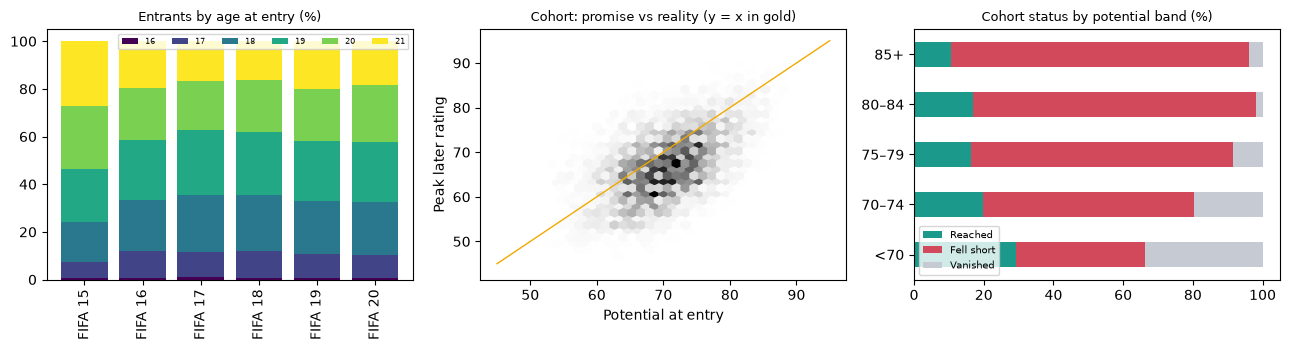

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
age_by_ed_l = pd.crosstab(learn["entry_edition_label"], learn["age"])
(age_by_ed_l.div(age_by_ed_l.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=axes[0], colormap="viridis", width=0.8)
axes[0].set_title("Entrants by age at entry (%)", fontsize=9); axes[0].legend(fontsize=6, ncol=6); axes[0].set_xlabel("")

nv = coh[coh["status"] != config.STATUS_VANISHED]
axes[1].hexbin(nv["potential"], nv["peak_later"].astype(float), gridsize=30, cmap="Greys", mincnt=1)
axes[1].plot([45, 95], [45, 95], color=config.PALETTE["promise"], lw=1)
axes[1].set_xlabel("Potential at entry"); axes[1].set_ylabel("Peak later rating")
axes[1].set_title("Cohort: promise vs reality (y = x in gold)", fontsize=9)

sb = pd.crosstab(coh["potential_band"], coh["status"], normalize="index")[
    [config.STATUS_REACHED, config.STATUS_FELL_SHORT, config.STATUS_VANISHED]] * 100
sb.plot.barh(stacked=True, ax=axes[2], color=[config.PALETTE["reality"], config.PALETTE["fell_short"], config.PALETTE["context"]])
axes[2].set_title("Cohort status by potential band (%)", fontsize=9); axes[2].legend(fontsize=7); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

## 11. Write to `reports/data_quality.md`

In [18]:
checks = pd.DataFrame(CHECKS)
reg_md = reg_cmp.reset_index().rename(columns={"band": "Band"})
miss_md = miss.reset_index().rename(columns={"edition_label": "Edition"})
miss_md.columns = ["Edition"] + [f"{c} missing %" for c in miss_cols]
body = f'''
### Filters (cohort)

{log.to_markdown()}

### Filters (learning cohorts)

{llog.to_markdown()}

### §7 regression: FIFA 15 under-21s by band

{dq.df_to_md(reg_md)}

### Missing values

Face stats (`pace` to `physic`) are blank for goalkeepers by design and left as NaN; GKs are excluded
from attribute analysis.

{dq.df_to_md(face_tbl.reset_index().rename(columns={"index": "Group"}))}

Missing rates (%) by edition. Missing counts across all editions: {", ".join(f"`{k}` {v:,}" for k, v in miss_n.items())}.

{dq.df_to_md(miss_md)}

### Outliers (logged, not dropped)

{dq.df_to_md(out_tbl.reset_index().rename(columns={"index": "Rule"}))}

### Cohort

- Cohort size: {len(coh):,} entrants ({", ".join(f"{k} {v:,}" for k, v in coh["entry_edition_label"].value_counts().sort_index().items())}).
- Already peaked at entry (overall = potential), to be excluded from accuracy metrics: **{n_peaked:,}**.
- Status: {", ".join(f"{k} {v:,}" for k, v in coh["status"].value_counts().items())}.
- Learning cohorts (FIFA 15 to 20): {len(learn):,} entrants; already peaked: {int(learn["already_peaked"].sum()):,}
  ({", ".join(f"{k} {int(v)}" for k, v in lsum["already_peaked"].items())}).

{dq.df_to_md(status_by_band.reset_index().rename(columns={"potential_band": "Band"}))}

### Notes

{chr(10).join("- " + n for n in NOTES)}

### Checks

{dq.df_to_md(checks)}
'''
dq.write_section("01", "01 FIFA clean", body)
print("Written to", config.DATA_QUALITY.relative_to(ROOT))

Written to reports/data_quality.md


## 12. Summary

In [19]:
display(checks)
print("\nNotes:")
for n in NOTES:
    print(" -", n)
assert (checks["Result"] == "PASS").all(), checks[checks["Result"] == "FAIL"]

,Check,Result,Detail
0,"Shape is 180,021 rows x 109 columns",PASS,"got (180021, 109)"
1,"53,111 unique player_id",PASS,"got 53,111"
2,"No duplicate (player_id, fifa_version) pairs",PASS,0 duplicates
3,Rows per edition match,PASS,
4,Date per edition matches (one date each),PASS,
5,Under-21s with potential >= 85 per edition match,PASS,
6,"FIFA 15 under-21s = 4,594",PASS,"got 4,594"
7,FIFA 15 band table: n matches,PASS,
8,FIFA 15 band table: reached matches,PASS,
9,FIFA 15 band table: vanished matches,PASS,



Notes:
 - FIFA `league_name` is each club's FC 24 league repeated across editions; 26,973 rows (FIFA 15–23) carry a league name that is wrong for that edition. Added `league_name_edition` (from `league_id`) and `league_country` (from male_teams); use those.
 - 1 goalkeeper row(s) have face stats filled in (Marlon Barninho FIFA 21). Left as is; GKs are excluded from attribute analysis anyway.
 - 1,524 players have more than one DOB across editions (EA corrections). cohort.parquet keeps `dob` (at entry) plus `dob_variants` (all variants, '|'-separated) for notebook 02.
 - 7 cohort entrants were aged over 21 in an earlier edition but 21 or under in their entry edition, because EA changed their DOB. Kept under the literal §6 rule; IDs: 228407, 235140, 225861, 214008, 224094, 221772, 220033.
